In [72]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [73]:
df = pd.read_csv("features_30_sec.csv")
df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues


In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   object 
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   float64
 14  harmony_mean             

In [75]:
df.describe()

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,662030.846000,0.378682,0.086340,0.130930,0.003051,2201.780898,4.696916e+05,2242.541070,137079.155165,4571.549304,...,1.148144,60.730958,-3.966028,62.633624,0.507696,63.712586,-2.328761,66.231930,-1.095348,70.126096
std,1784.073992,0.081705,0.007735,0.065683,0.003634,715.960600,4.008995e+05,526.316473,96455.666326,1574.791602,...,4.578948,33.781951,4.549697,33.479172,3.869105,34.401977,3.755957,37.174631,3.837007,45.228512
min,660000.000000,0.171939,0.044555,0.005276,0.000004,570.040355,7.911251e+03,898.066208,10787.185064,749.140636,...,-15.693844,9.169314,-17.234728,13.931521,-11.963694,15.420555,-18.501955,13.487622,-19.929634,7.956583
25%,661504.000000,0.319562,0.082298,0.086657,0.000942,1627.697311,1.843505e+05,1907.240605,67376.554428,3380.069642,...,-1.863280,40.376442,-7.207225,40.830875,-2.007015,41.884240,-4.662925,41.710184,-3.368996,42.372865
50%,661794.000000,0.383148,0.086615,0.122443,0.001816,2209.263090,3.384862e+05,2221.392843,111977.548036,4658.524473,...,1.212809,52.325077,-4.065605,54.717674,0.669643,54.804890,-2.393862,57.423059,-1.166289,59.186117
75%,661794.000000,0.435942,0.091256,0.175682,0.003577,2691.294667,6.121479e+05,2578.469836,182371.576801,5533.810460,...,4.359662,71.691755,-0.838737,75.040838,3.119212,75.385832,0.150573,78.626444,1.312615,85.375374
max,675808.000000,0.663685,0.108111,0.397973,0.027679,4435.243901,3.036843e+06,3509.646417,694784.811549,8677.672688,...,13.457150,392.932373,11.482946,406.058868,15.388390,332.905426,14.694924,393.161987,15.369627,506.065155


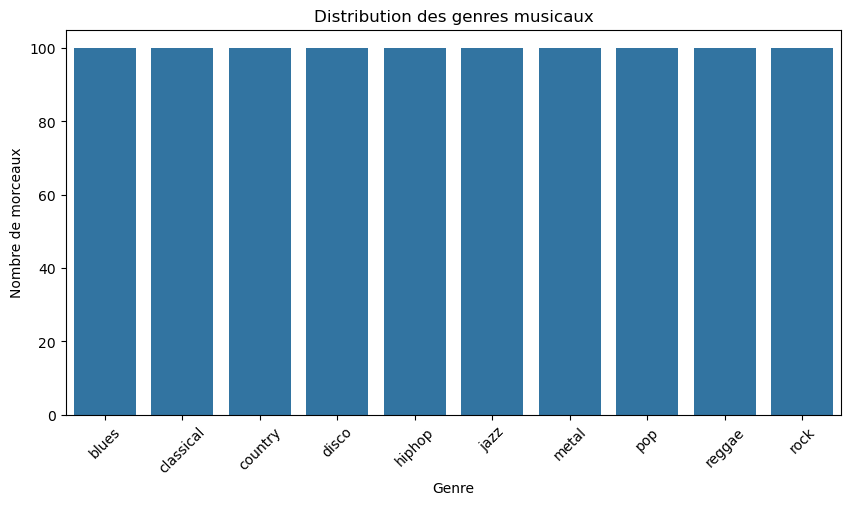

In [76]:
#distribution du genre
plt.figure(figsize=(10,5))
sns.countplot(x="label",data=df,order=df["label"].value_counts().index)
plt.title("Distribution des genres musicaux")
plt.xlabel("Genre")
plt.ylabel("Nombre de morceaux")
plt.xticks(rotation=45)
plt.show()

La distribution des genres musicaux apparaît nettement  équilibrée. 
Chaque genre est représenté par un nombre similaire d'observations,
ce qui limite les risques de biais liés à un déséquilibre des classes 
lors de l'entraînement des modèles de classification.

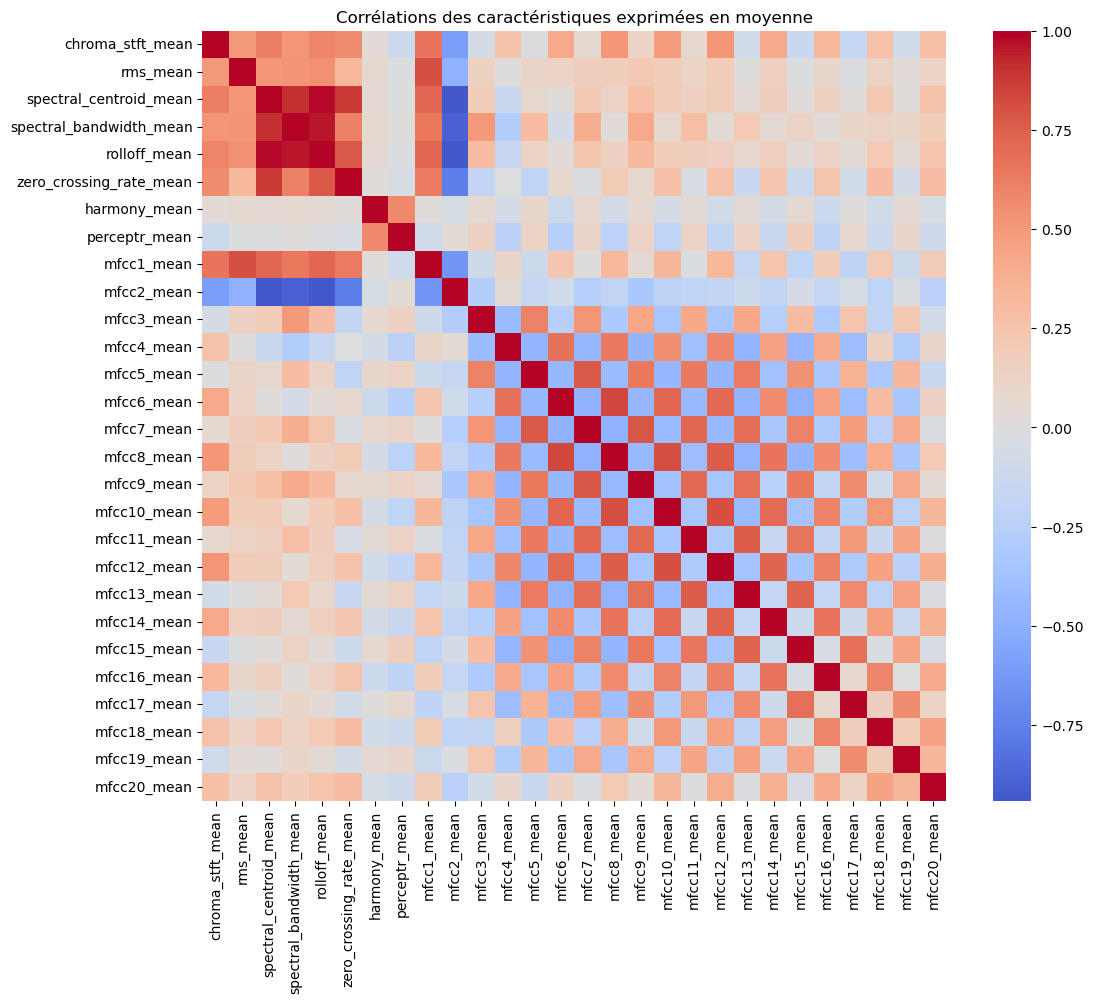

In [77]:
# corrélation des descripteurs 
mean_cols = [col for col in df.columns if "_mean" in col]
corr_mean = df[mean_cols].corr()
#corr_mean[corr_mean>0.85 ]
plt.figure(figsize=(12,10))
sns.heatmap(corr_mean, cmap="coolwarm", center=0)
plt.title("Corrélations des caractéristiques exprimées en moyenne")
plt.show()

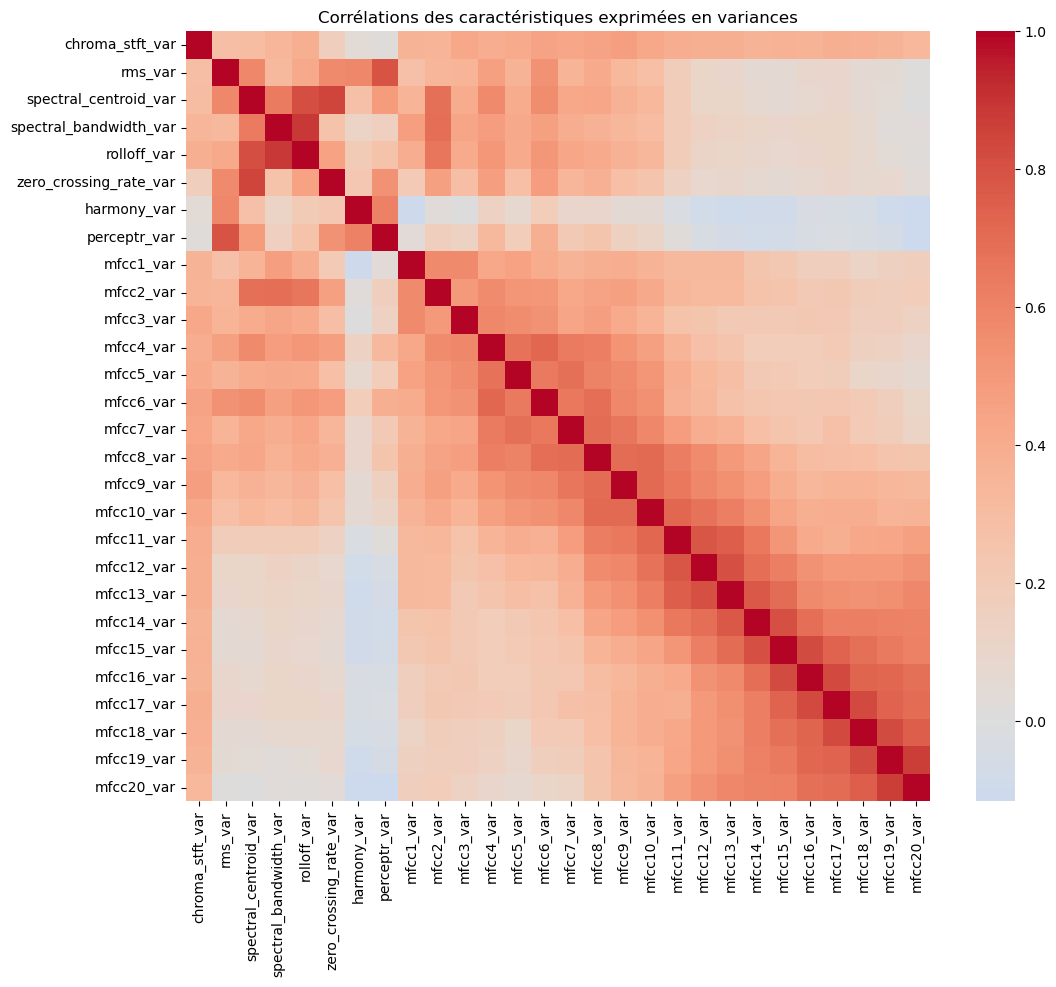

In [78]:
var_cols = [col for col in df.columns if "var" in col]
corr_val = df[var_cols].corr()
#corr_val[corr_val>0.85 ]
plt.figure(figsize=(12,10))
sns.heatmap(corr_val, cmap="coolwarm", center=0)
plt.title("Corrélations des caractéristiques exprimées en variances")
plt.show()

Ces matrices de corrélation mettent en évidence plusieurs paires de variables fortement corrélées.
Cette observation révèle une certaine redondance de l'information contenue dans les caractéristiques audio extraites.
En effet, les corrélations élevées observées suggèrent que certaines variables capturent des aspects similaires,
voire très proches, du signal musical. Cette redondance est particulièrement visible parmi certaines caractéristiques
spectrales et coefficients MFCC, qui décrivent des propriétés fréquentielles apparentées.
À l'inverse, de nombreuses variables présentent des corrélations faibles ou modérées,ce qui indique qu'elles
apportent des informations complémentaires et potentiellement utiles à la discrimination des genres musicaux.


In [79]:
# comportement du genre en fonc  tion des caractéristiques
# boxplot
def boxplot(variable_x,variable_y,data):
    plt.figure(figsize=(12,6))
    sns.boxplot(x=variable_x,y=variable_y,data=data)
    plt.xticks(rotation=45)
    plt.title(f"Boxplot de {variable_y} selon {variable_x}",fontsize=15,fontweight="bold")
    plt.xlabel(variable_x,fontsize=13)
    plt.ylabel(variable_y,fontsize=13)
    plt.show()

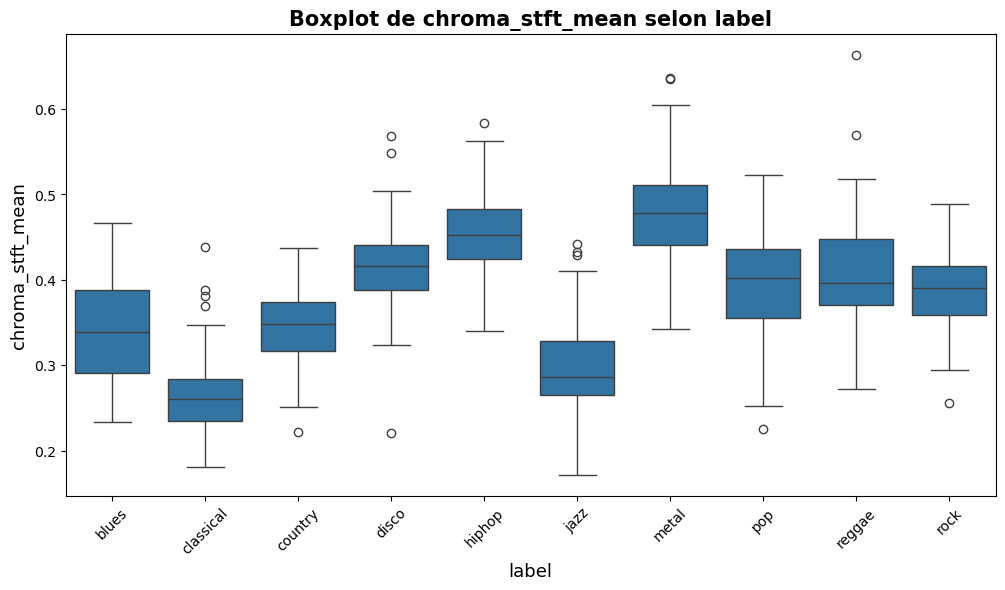

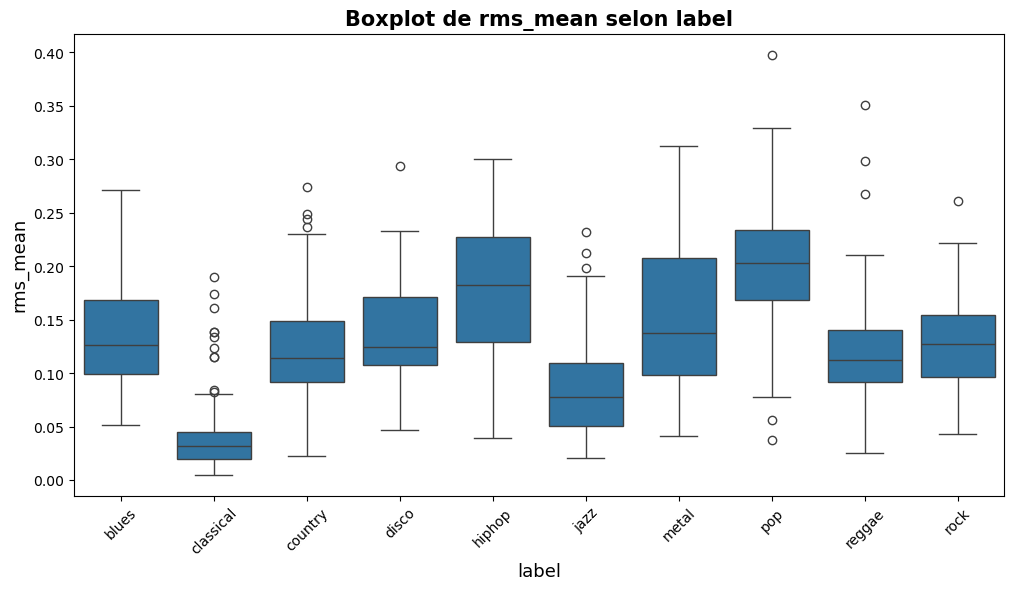

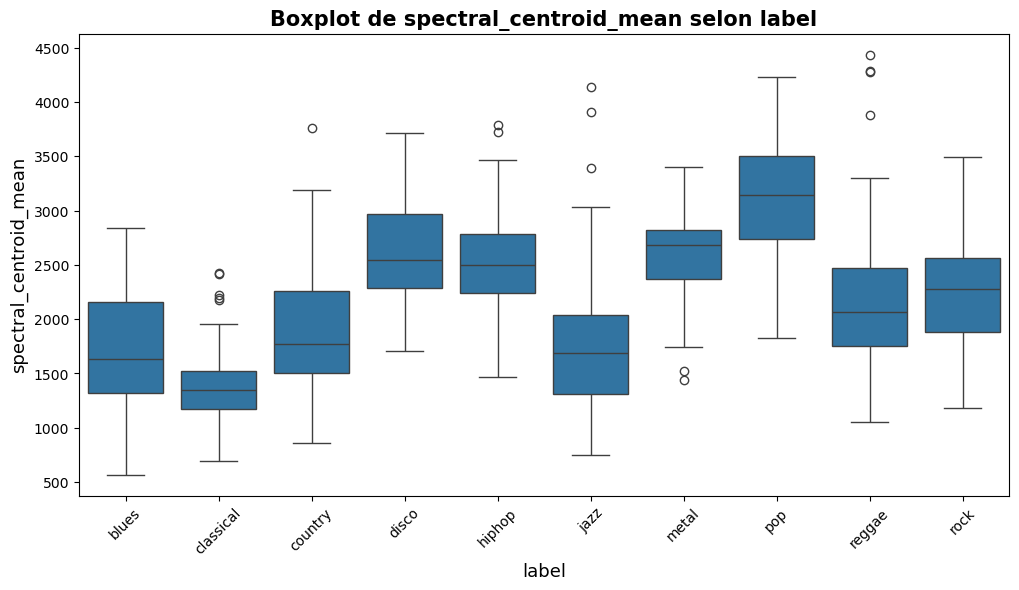

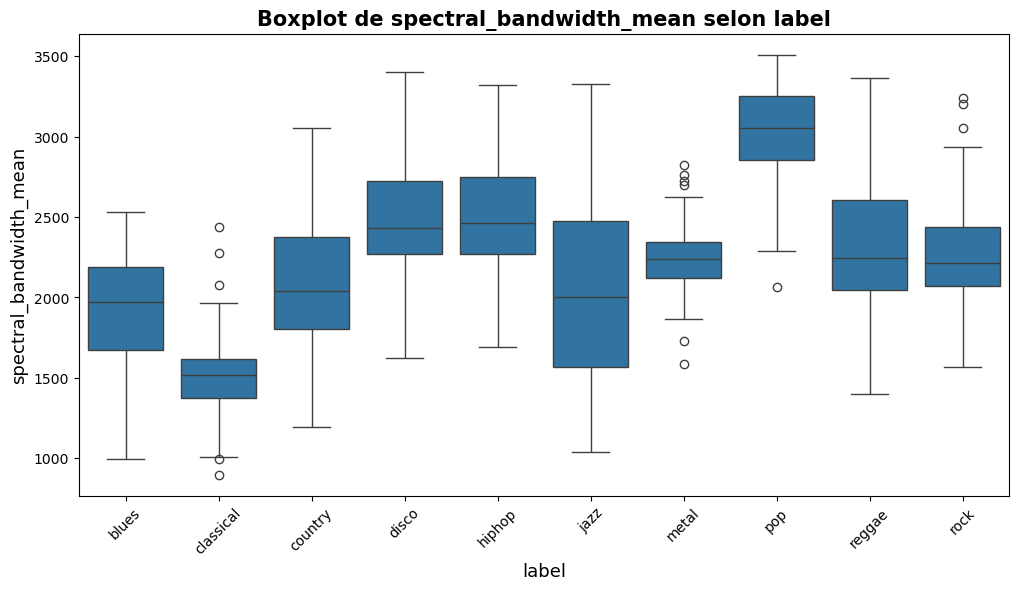

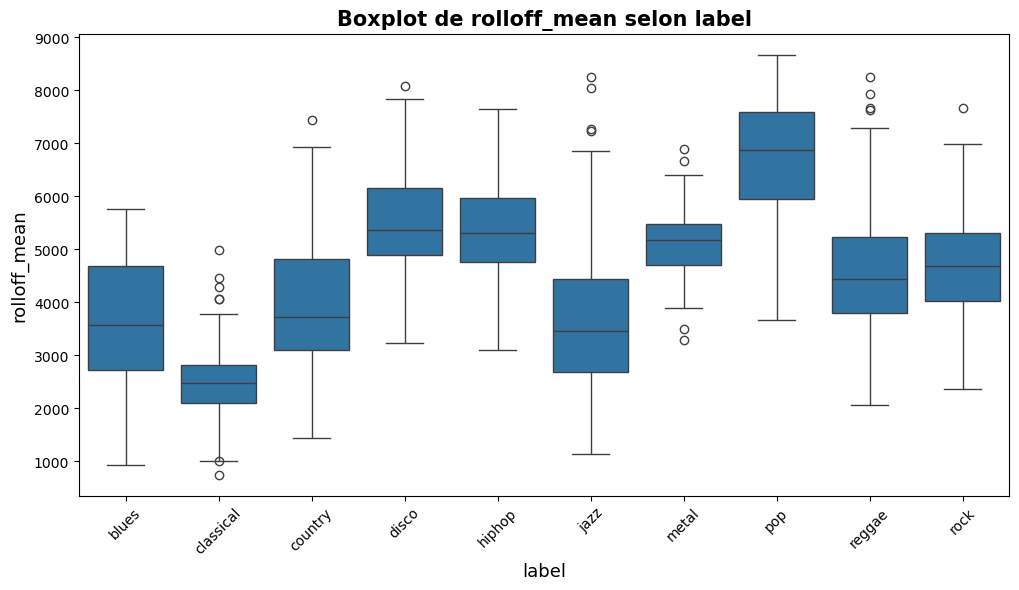

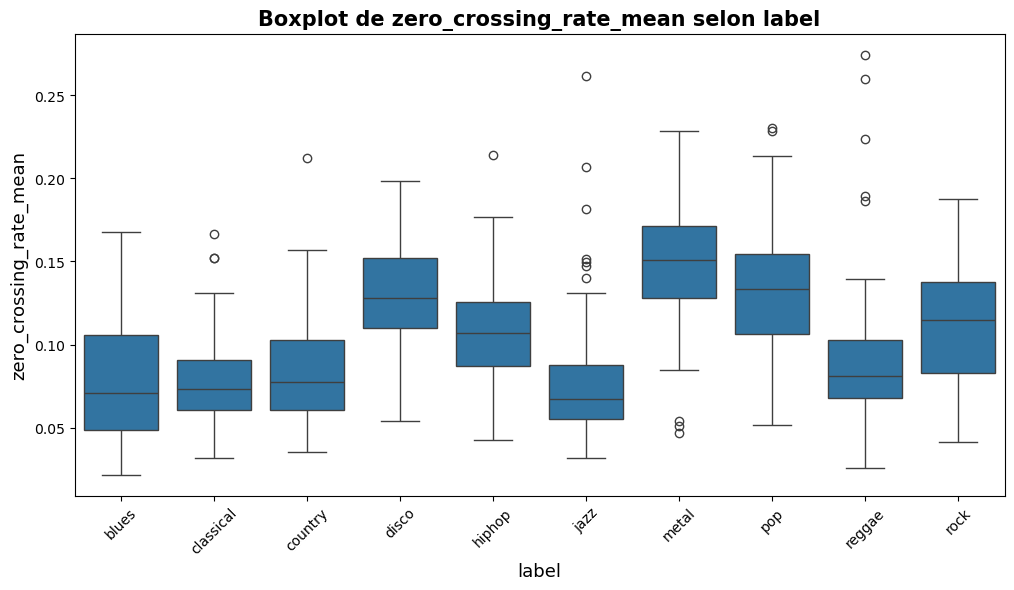

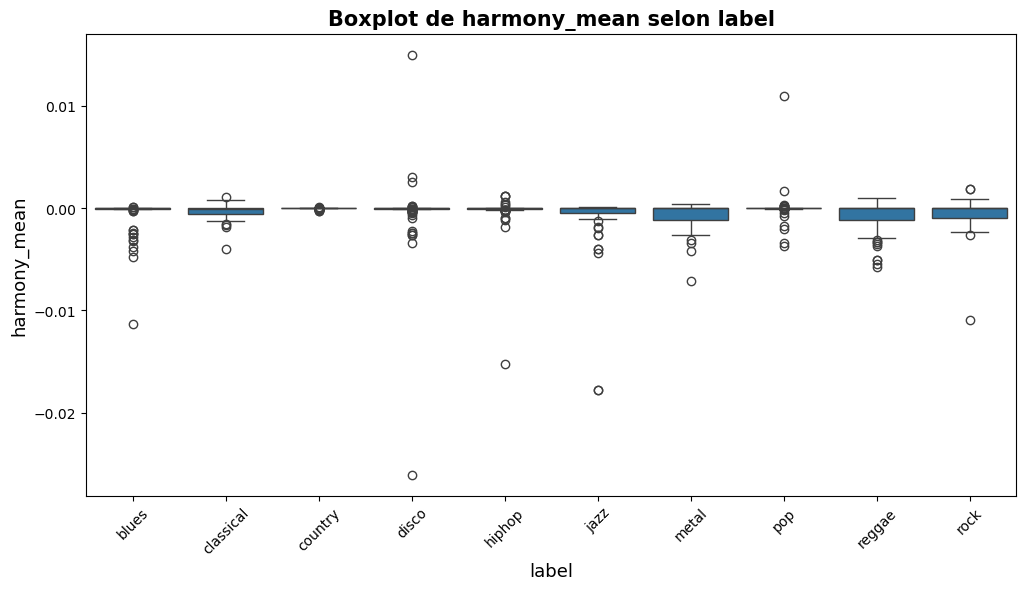

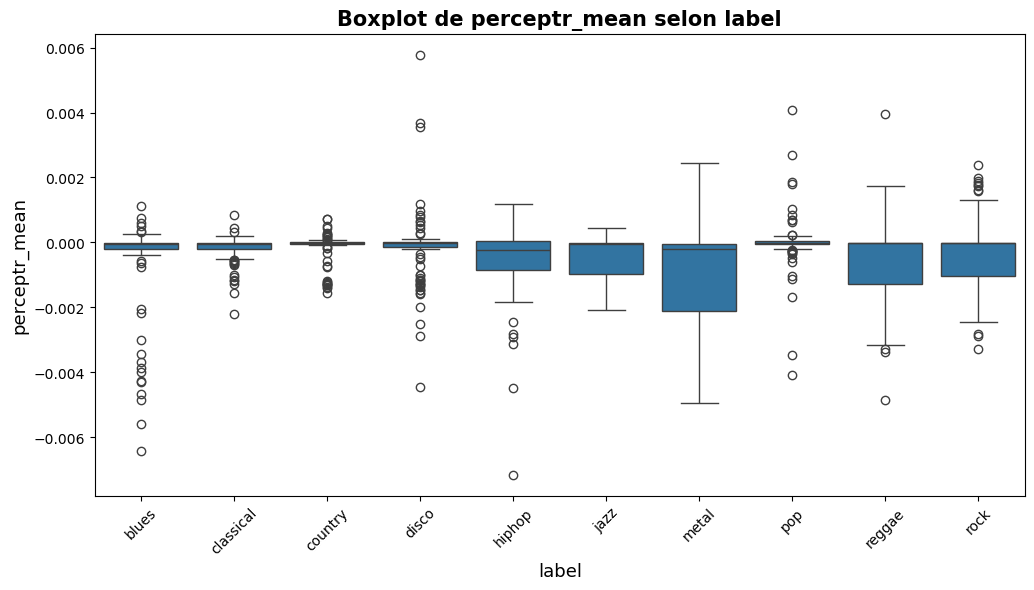

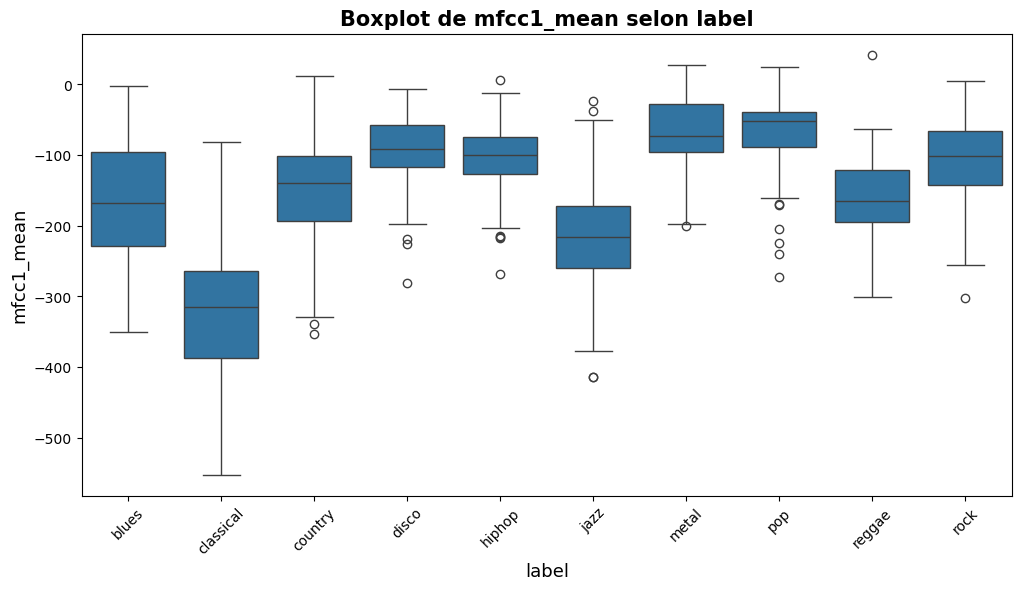

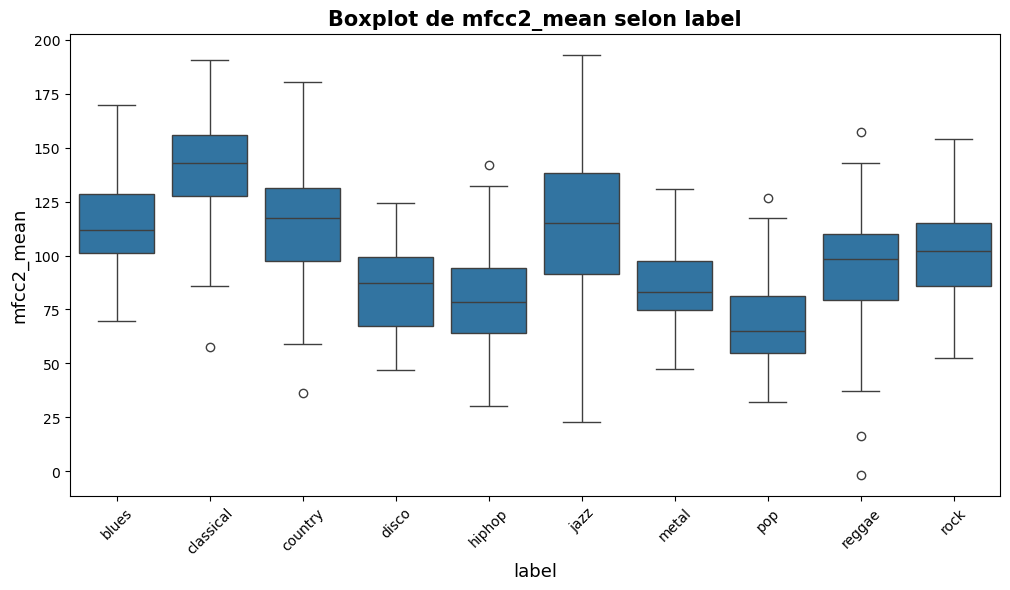

In [80]:
#echantillon de variables explicatives pour le boxplot
echantillon = [var for var in mean_cols if "mfcc" not in var ] +["mfcc1_mean","mfcc2_mean"]
for i in echantillon:
    boxplot(variable_x = "label",variable_y=i,data=df)

D'après cette série de boxplots, on observe deux tendances principales.
Un premier groupe de descripteurs présente des médianes sensiblement
différentes selon les genres musicaux, ce qui suggère un potentiel 
pouvoir discriminatoire chez ces caractéristiques.À l'inverse,
un second groupe constitué notamment de harmony_mean et perceptr_mean 
présente des médianes relativement proches d'un genre à l'autre.
Cette observation laisse à croire que, prises isolément, ces variables offrent 
une capacité de séparation plus limitée ou quasi-inexistante entre les genres musicaux.

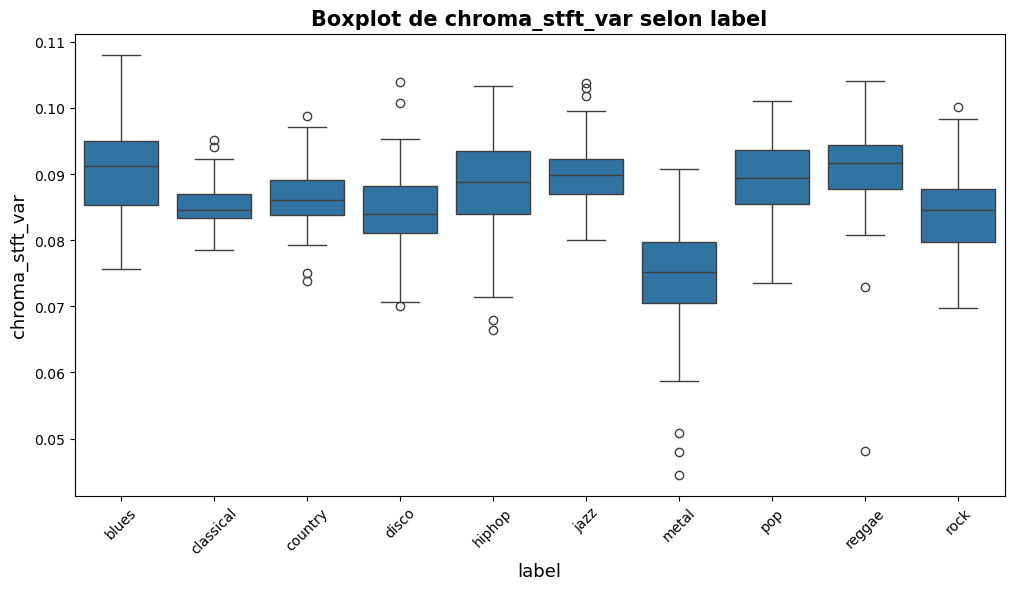

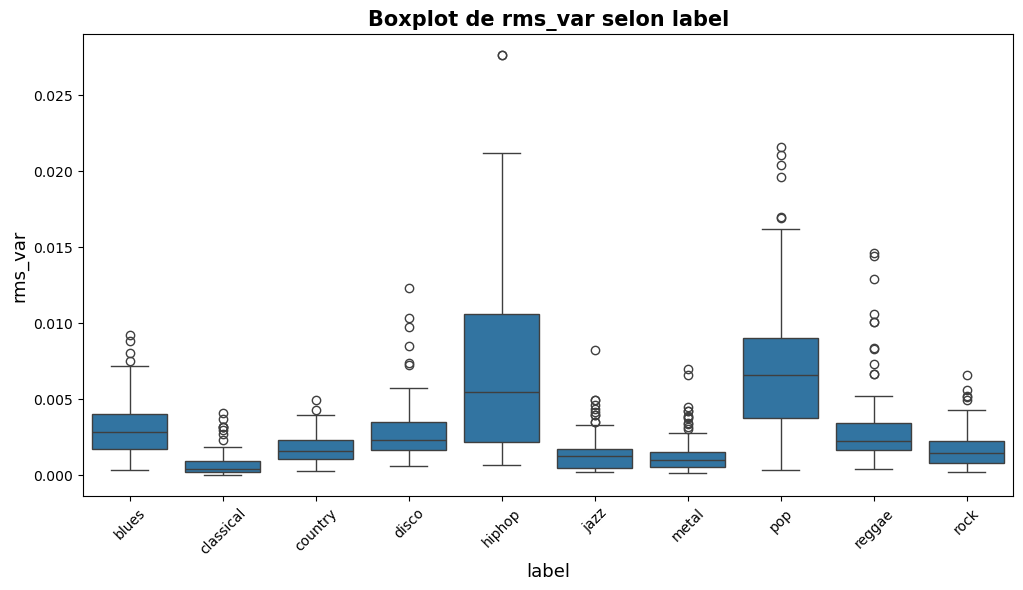

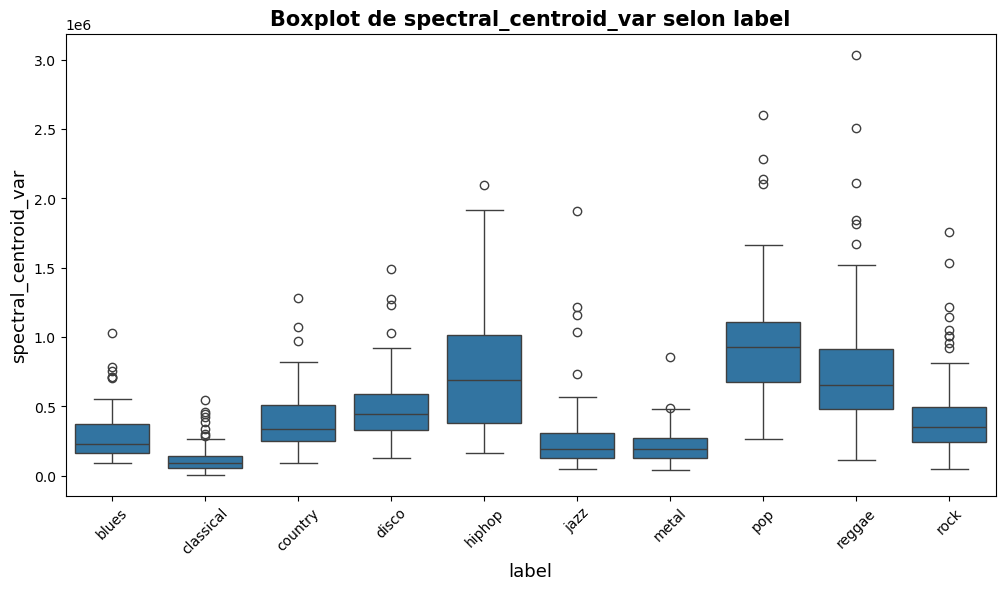

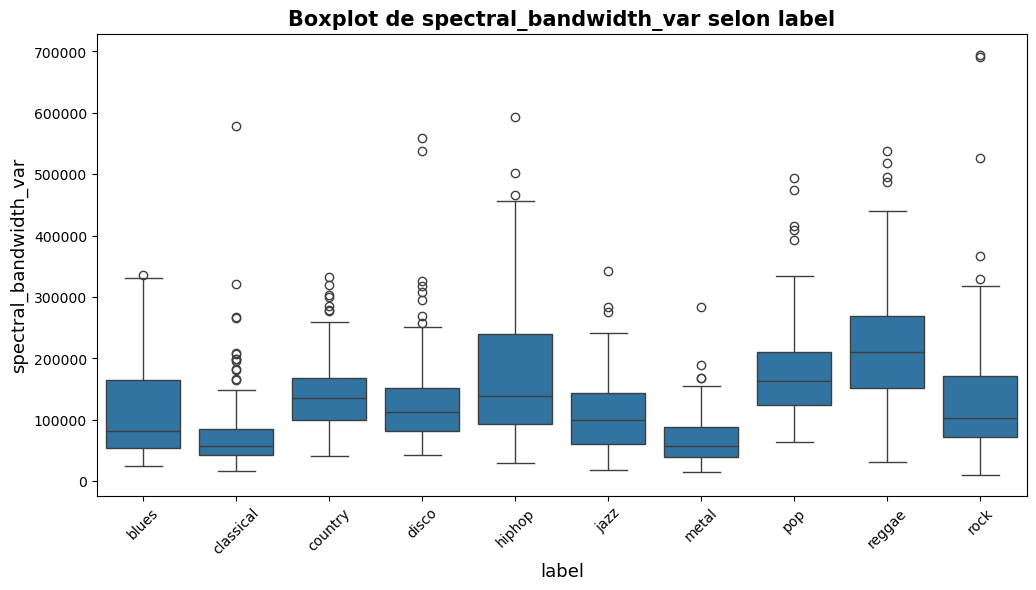

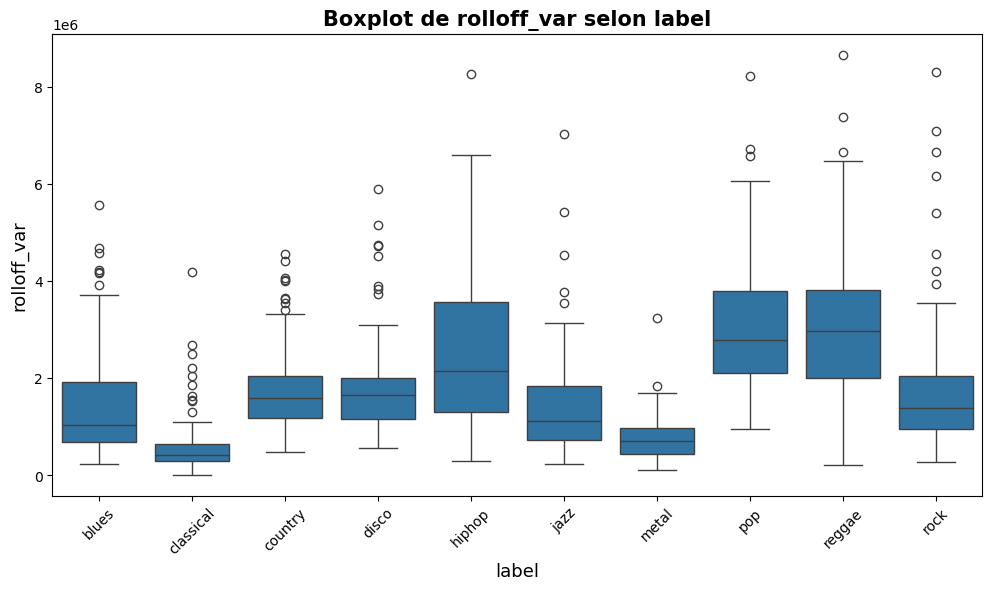

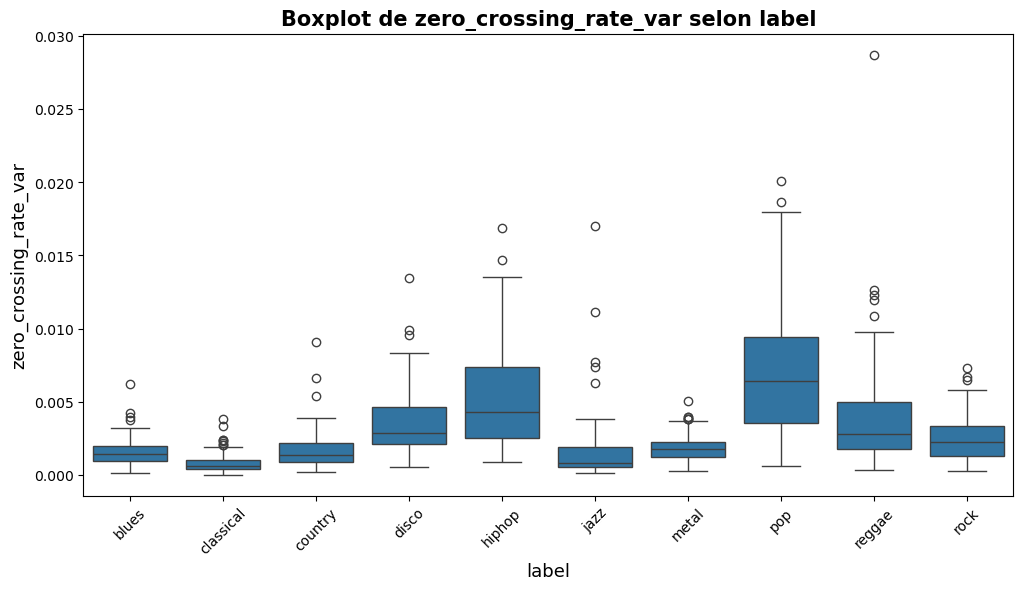

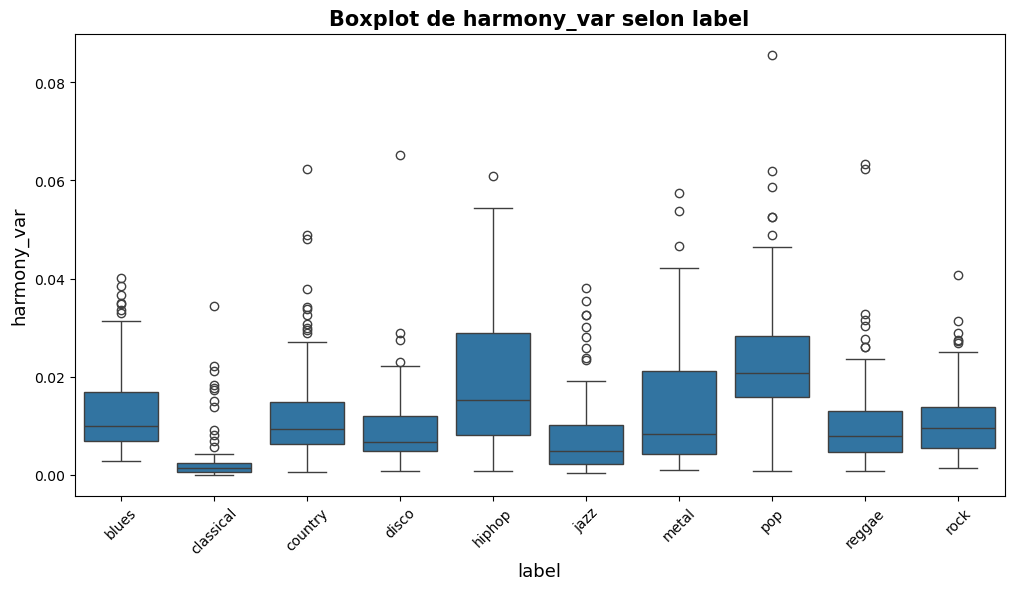

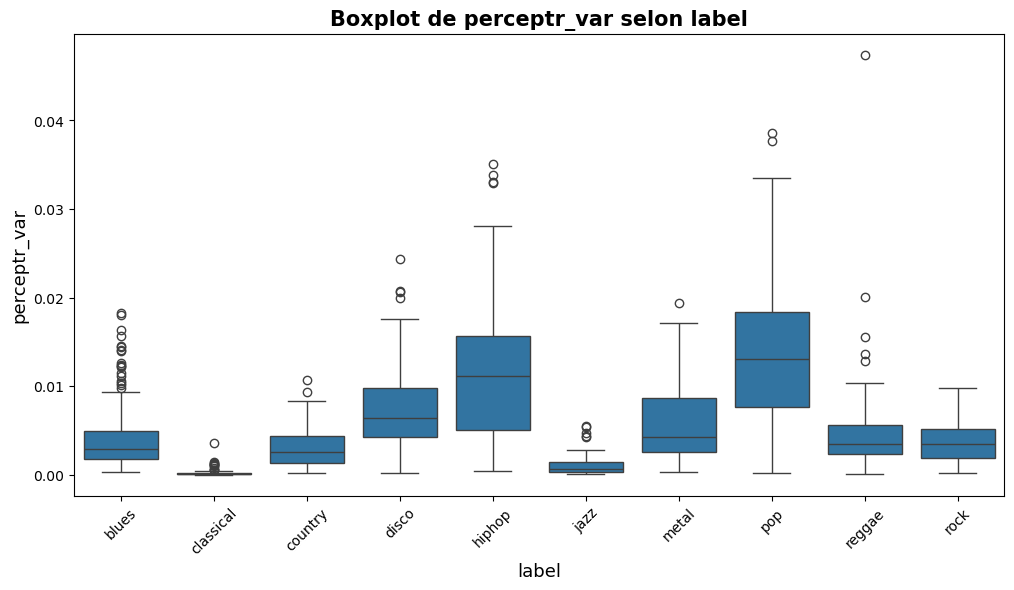

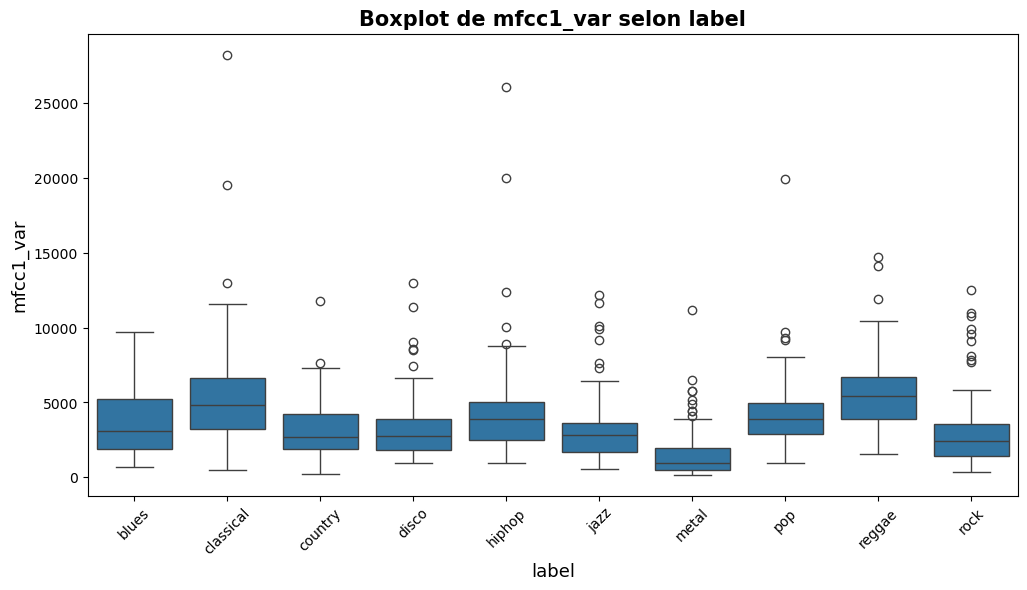

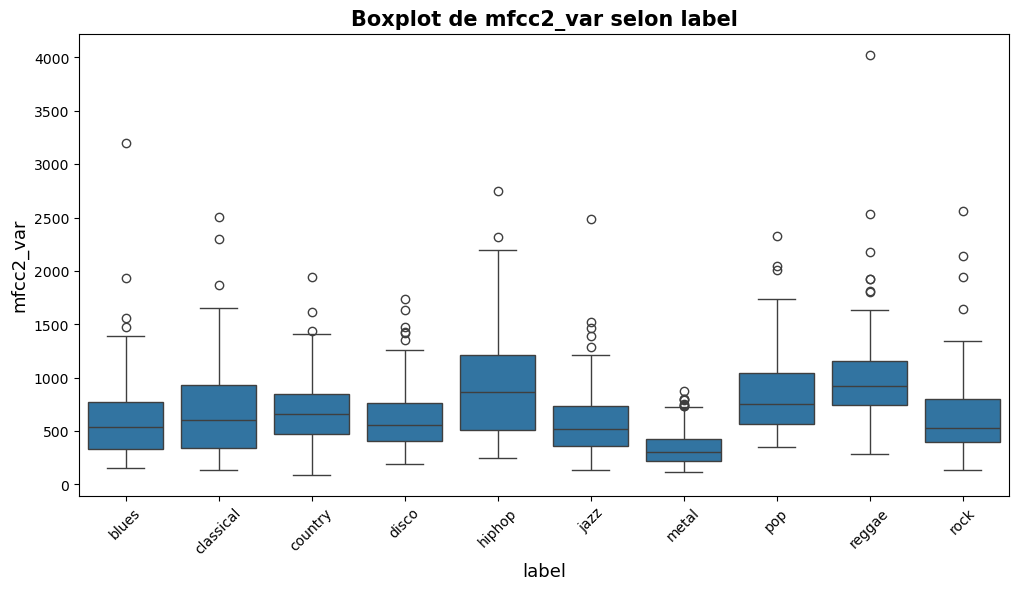

In [81]:
#echantillon de variables explicatives pour le boxplot
echantillon2 = [var for var in var_cols if "mfcc" not in var ] +["mfcc1_var","mfcc2_var"]
for i in echantillon2:
    boxplot(variable_x = "label",variable_y=i,data=df)
    

Avec ces graphiques , on constate ici des médianes qui sont potentiellement différentes,ce qui 
souligne également chez variables en variances une possibilité de contribution à la séparation de genres musicaux.
Toutefois, notons que les deux descriteurs dont les moyennes ci-dessus semblent apporté une faible
contribution à la différenciation des chansons ont toutes leur variances contributives à la tâche 
de séparation des genres musicaux:on pourrait en déduire donc que ces deux caractéristiques 
varient tout au long des morçeaux.

In [82]:
X = df.drop(columns = ["filename","label","length"])
y = df["label"]
print(X.shape,y.shape)


(1000, 57) (1000,)


In [83]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler , StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split

In [84]:
def encodage(y,y2):
    encoder = LabelEncoder()
    y= encoder.fit_transform(y)
    y2= encoder.transform(y2)
    return y,y2

In [85]:
def scaling(X,X2):
    scaler=StandardScaler()
    X= scaler.fit_transform(X)
    X2 = scaler.transform(X2)
    return X,X2

In [86]:
def preprocessing(X,X2,y,y2):
    y,y2= encodage(y,y2)
    X,X2= scaling(X,X2)
    return X,X2,y,y2

In [87]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [88]:
X_train_scaled , X_test_scaled , y_train_scaled , y_test_scaled = preprocessing(X_train , X_test , y_train , y_test)

In [89]:
print(X_train_scaled.shape,y_train_scaled.shape)
print(X_test_scaled.shape,y_test_scaled.shape)

(800, 57) (800,)
(200, 57) (200,)


In [90]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score,classification_report,confusion_matrix,accuracy_score,recall_score

In [154]:

XGB_model = XGBClassifier()
SVC_model = SVC()
RandomF_model = RandomForestClassifier(random_state = 42)
logistic_model = LogisticRegression()
DecisionTree_model =DecisionTreeClassifier()
KNN = KNeighborsClassifier(n_neighbors=8)


In [175]:
modeles = {"LogisticRegression"         :logistic_model,
            "DecisionTreeClassifier"    :DecisionTree_model,
                "RandomForestClassifier":RandomF_model,
                "SVC"                   : SVC_model,
                "KNeighborsClassifier"  :KNN,
           "XGBClassifier"              : XGB_model}

In [176]:
def evaluation(model,X_train,y_train,X_test,y_test):
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    score = f1_score(y_test,y_pred,average='macro')
    print("f1_score:",score)
    print("accuracy_score:",accuracy_score(y_test,y_pred))
    print(confusion_matrix(y_test,y_pred))
    print("classification_report:\n",classification_report(y_test,y_pred))

In [177]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
for name , model in modeles.items():
    print(name)
    evaluation(model,X_train_scaled,y_train_scaled,X_test_scaled,y_test_scaled)

LogisticRegression
f1_score: 0.7107346142452526
accuracy_score: 0.71
[[13  0  2  0  0  2  0  0  2  1]
 [ 0 19  0  0  0  1  0  0  0  0]
 [ 2  0 14  0  0  1  0  0  1  2]
 [ 0  0  0 10  4  1  0  2  1  2]
 [ 1  0  0  1 12  0  0  0  6  0]
 [ 1  1  0  0  0 17  0  0  0  1]
 [ 2  0  0  0  1  0 16  0  0  1]
 [ 0  0  0  1  1  0  0 16  2  0]
 [ 0  0  1  1  2  1  0  0 14  1]
 [ 0  0  5  0  0  1  1  1  1 11]]
classification_report:
               precision    recall  f1-score   support

           0       0.68      0.65      0.67        20
           1       0.95      0.95      0.95        20
           2       0.64      0.70      0.67        20
           3       0.77      0.50      0.61        20
           4       0.60      0.60      0.60        20
           5       0.71      0.85      0.77        20
           6       0.94      0.80      0.86        20
           7       0.84      0.80      0.82        20
           8       0.52      0.70      0.60        20
           9       0.58      0.55  

Après cette évaluation sans aucun traitement particulier des variables,
les modèles les plus performants sont : SVC,Xgboost,LogisticRegression.
Mais,on constate que les deux dernières classes (reggae et rock) ne se laissent pas bien distinguer quel que soit le modèle.
Il en est de même pour la classe 3 et légèrement moins pour la classe 4


In [178]:

# Courbe d'apprentissage 
from sklearn.model_selection import learning_curve
def learningCurve(model,X_train_scaled,y_train_scaled):
    N , train_score , test_score = learning_curve(model , X=X_train_scaled ,y=y_train_scaled , cv = 5 ,train_sizes = np.linspace(0.1 , 1.0 ,10) , scoring = "f1_macro") 
    plt.plot(N , train_score.mean(axis = 1),label = "train_score")
    plt.xlabel("train_data") 
    plt.plot(N , test_score.mean(axis = 1), label = "test_score")
    plt.ylabel(" les scores" ) 
    plt.legend()
    plt.grid(True)
    plt.show()


                                        Essaies pour bonifier les performances

In [179]:
#suppression des colonnes fortement corrélées

# Sélection du triangle supérieur (sans la diagonale) pour éviter les doublons et l'auto-corrélation
corrs = corr_mean.abs().where(np.triu(np.ones(corr_mean.shape), k=1).astype(bool))

# Identification des colonnes à supprimer (seuil > 0.95)
a_supprimer = [column for column in corrs.columns if any(corrs[column] > 0.95)] 

new_df = df.drop(columns=a_supprimer)
new_df.shape


(1000, 59)

La suppression des variables identifiées
plus  haut comme non contributive dans la
classe de classification des genres musicaux 
n'a rien apporté aux modèles.

In [180]:
X_new = new_df.drop(columns = ["filename","label","length"])
y_new= new_df["label"]

X_train_new , X_test_new , y_train_new , y_test_new = train_test_split(X_new,y_new,test_size=0.2,random_state=42,stratify=y_new)
X_train_new , X_test_new , y_train_new , y_test_new = preprocessing(X_train_new , X_test_new , y_train_new , y_test_new)

In [181]:
for name,model in modeles.items():
    print(name,"...")
    evaluation(model,X_train_new,y_train_new,X_test_new,y_test_new) 


LogisticRegression ...
f1_score: 0.7064557575273716
accuracy_score: 0.705
[[13  0  2  0  0  2  0  0  2  1]
 [ 0 19  0  0  0  1  0  0  0  0]
 [ 2  0 14  0  0  1  0  0  1  2]
 [ 0  0  0 10  4  1  0  2  1  2]
 [ 1  0  0  1 12  0  0  0  6  0]
 [ 1  1  0  0  0 17  0  0  0  1]
 [ 2  0  0  0  1  0 15  0  0  2]
 [ 0  0  0  1  1  0  0 16  2  0]
 [ 0  0  0  1  2  1  0  0 14  2]
 [ 0  0  5  0  0  1  1  1  1 11]]
classification_report:
               precision    recall  f1-score   support

           0       0.68      0.65      0.67        20
           1       0.95      0.95      0.95        20
           2       0.67      0.70      0.68        20
           3       0.77      0.50      0.61        20
           4       0.60      0.60      0.60        20
           5       0.71      0.85      0.77        20
           6       0.94      0.75      0.83        20
           7       0.84      0.80      0.82        20
           8       0.52      0.70      0.60        20
           9       0.52      0

La suppression à elle seule d'une colonne d'une paire fortement correlée n'a été d'aucune 
utilité pour tous les modèles à l'exception de SVC ,nous avons toujours 
logisticRegresion et Xgboost qui ont encore des des performances pertinentes
mais relativement inférieure à celles de la préccédente évaluation.


In [182]:
#Essaie avec les outliers 

Q1 = df.select_dtypes(include=['number']).quantile(0.25)
Q3 = df.select_dtypes(include=['number']).quantile(0.75)
IQR = Q3 - Q1
masque = ~((df.select_dtypes(include=['number']) < (Q1 - 1.5 * IQR)) | (df.select_dtypes(include=['number'])
                                                                         > (Q3 + 1.5 * IQR))).any(axis=1)
df_nettoye = df[masque]
df_nettoye.shape

(398, 60)

In [183]:
X_clean = df_nettoye.drop(columns = ["filename","label","length"])
y_clean = df_nettoye["label"]

X_train_clean , X_test_clean , y_train_clean , y_test_clean = train_test_split(X_clean,y_clean,test_size=0.2,random_state=42,stratify=y_clean)
X_train_clean , X_test_clean , y_train_clean , y_test_clean = preprocessing(X_train_clean , X_test_clean , y_train_clean , y_test_clean)

In [184]:
for name,model in modeles.items():
    print(name,"...")
    evaluation(model,X_train_clean ,y_train_clean , X_test_clean ,  y_test_clean) 


LogisticRegression ...
f1_score: 0.6230294260255655
accuracy_score: 0.6
[[ 4  0  1  0  1  0  1  0  1  1]
 [ 0  4  0  0  0  0  0  0  0  0]
 [ 1  0 11  1  0  0  0  0  0  1]
 [ 0  0  2  7  1  0  1  0  1  0]
 [ 0  0  0  0  5  0  0  0  1  0]
 [ 0  0  0  0  0  6  0  0  1  0]
 [ 0  0  0  1  0  0  3  0  0  3]
 [ 0  0  1  2  0  0  0  2  0  0]
 [ 1  0  0  1  0  0  0  0  4  0]
 [ 0  0  2  5  0  1  0  0  0  2]]
classification_report:
               precision    recall  f1-score   support

           0       0.67      0.44      0.53         9
           1       1.00      1.00      1.00         4
           2       0.65      0.79      0.71        14
           3       0.41      0.58      0.48        12
           4       0.71      0.83      0.77         6
           5       0.86      0.86      0.86         7
           6       0.60      0.43      0.50         7
           7       1.00      0.40      0.57         5
           8       0.50      0.67      0.57         6
           9       0.29      0.2


La suppression des valeurs aberrantes à fait  regressé en performance
les modèles,mais elle s'est légèrement montrer généreuse 
au modèle d'arbre de décision bien que nous ayons perdu assez d'informations.
Cela n'a exclut que SVC et XGBoost de rester toujours a 
la tête tout en ayant leur F1-score légèrement moins que 
celles qu'elles ont obtenu sur les données brute 
sans traitement particulier. 
Cela peut signifier que ces valeurs peuevnt comporter des capacités de discriminations 
des genres musicaux plutôt que du bruit. 

In [185]:

XGB_model = XGBClassifier()
SVC_model = SVC()
RamdomF_model = RandomForestClassifier(random_state = 42)
logistic_model = LogisticRegression()
DecisionTree_model =DecisionTreeClassifier()
KNN = KNeighborsClassifier()


In [186]:
def evaluation2(model,X_train,y_train,X_test,y_test):
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    score = f1_score(y_test,y_pred,average='macro')
    print("f1_score:",score)
    print("accuracy_score:",accuracy_score(y_test,y_pred))
    

In [187]:
evaluation2(XGB_model,X_train_scaled,y_train_scaled,X_test_scaled,y_test_scaled)

f1_score: 0.728591889312776
accuracy_score: 0.735


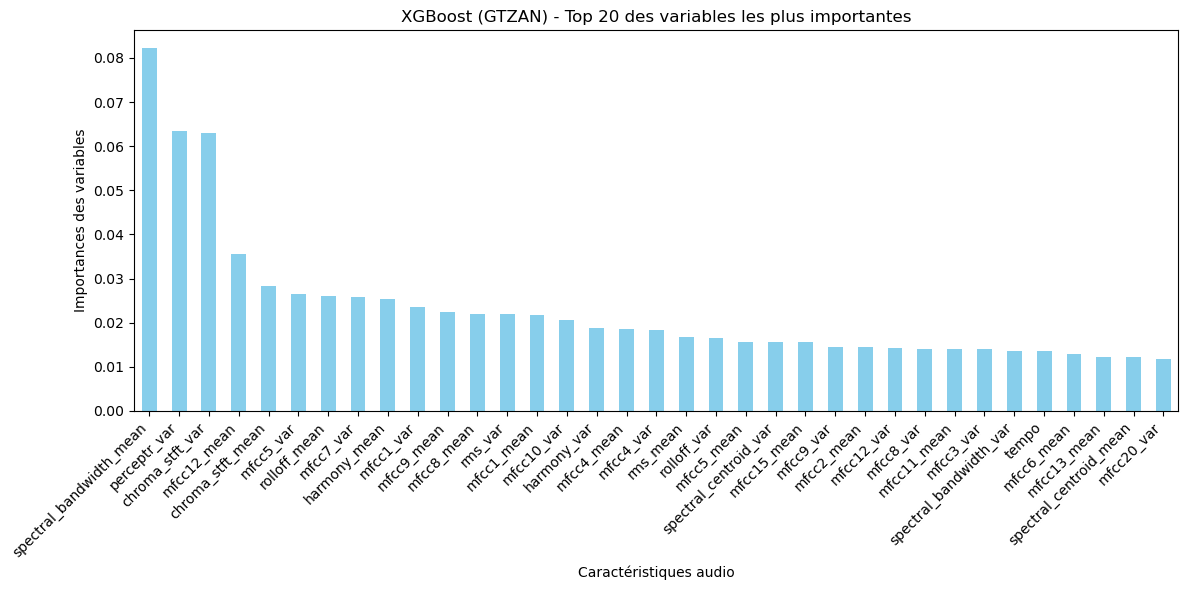

In [188]:
# Extraction des variables importantes triées par ordre décroissant pour XgbClassifier
xgb_importances = pd.Series(XGB_model.feature_importances_, 
        index=df.drop(columns=["filename", "label", "length"]).columns)
# On trie et 35 premières variables importantes pour Xgbosst bien entendu
xgb_importances_trie = xgb_importances.sort_values(ascending=False).head(35)

plt.figure(figsize=(12, 6))
xgb_importances_trie.plot(kind="bar", color="skyblue") 

plt.title("XGBoost (GTZAN) - Top 20 des variables les plus importantes")
plt.ylabel("Importances des variables") 
plt.xlabel("Caractéristiques audio")
# Rotation à 45 degrés des noms des variables pour éviter qu'ils ne se chevauchent
plt.xticks(rotation=45, ha="right") 
plt.tight_layout()
plt.show()



In [189]:
alpha=35 # on garde les alpha descripteurs les plus importants
top_descripteurs = xgb_importances_trie.index[:35].tolist()

In [190]:
# CONVERTION EN DF POUR LA SEPARATION 
X_train = pd.DataFrame(X_train,columns=X.columns)
X_test = pd.DataFrame(X_test,columns=X.columns)


In [191]:

X_train_reduit=X_train[top_descripteurs] 
X_train_reduit = X_train[top_descripteurs]
X_test_reduit  = X_test[top_descripteurs]

In [192]:
X_train_reduit, X_test_reduit = scaling(X_train_reduit,X_test_reduit)


In [193]:
for name,model in modeles.items():
    print(name,"...")
    evaluation2(model,X_train_reduit,y_train_scaled,X_test_reduit,y_test_scaled)

LogisticRegression ...
f1_score: 0.6838657396705619
accuracy_score: 0.685
DecisionTreeClassifier ...
f1_score: 0.48822908292779177
accuracy_score: 0.495
RandomForestClassifier ...
f1_score: 0.6951741408431735
accuracy_score: 0.705
SVC ...
f1_score: 0.7555315319846212
accuracy_score: 0.755
KNeighborsClassifier ...
f1_score: 0.735309195189153
accuracy_score: 0.735
XGBClassifier ...
f1_score: 0.7037172832975441
accuracy_score: 0.705


La selection des 35 variables  les plus importantes 
pour le modèle de XGBOOST  a été favorable
non seulement pour XGBOOST mais pour tous les 
autres modèles relativement à la suppression des valeurs abbérentes
et tous les autres évaluations.
Mais elle a nettement propulser les scores de SVC et KNN relativement 
a l'évaluation sur les données brutes (sans une préalable sélection de variables)
.


In [194]:
#Application de la PCA
from sklearn.decomposition import PCA
#On garde 95% de la variance totale de nos descripteurs d'audio
pca = PCA(n_components=0.96)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)



In [195]:
for name,model in modeles.items():
    print(name,"...")
    evaluation2(model,X_train_pca,y_train_scaled,X_test_pca,y_test_scaled)


LogisticRegression ...
f1_score: 0.6827084268832329
accuracy_score: 0.685
DecisionTreeClassifier ...
f1_score: 0.4410406924405872
accuracy_score: 0.45
RandomForestClassifier ...
f1_score: 0.6740144309656504
accuracy_score: 0.675
SVC ...
f1_score: 0.7301009734511241
accuracy_score: 0.73
KNeighborsClassifier ...
f1_score: 0.6942434585695176
accuracy_score: 0.695
XGBClassifier ...
f1_score: 0.6840530548682026
accuracy_score: 0.68


On constate que le modèle de 
SupportVectorMachnine s'en sort toujours 
avec la plus haute performance 
face à la reduction de la dimensionnalité,
sauf qu'avec un score moins que celui de la suppression des valeurs.
Mais ,le xgbost est pénalisé.

# COURBES D'APPRENTISAGE

LogisticRegression ...


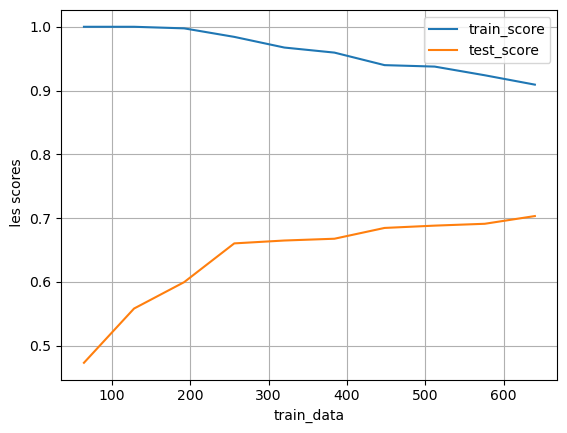

DecisionTreeClassifier ...


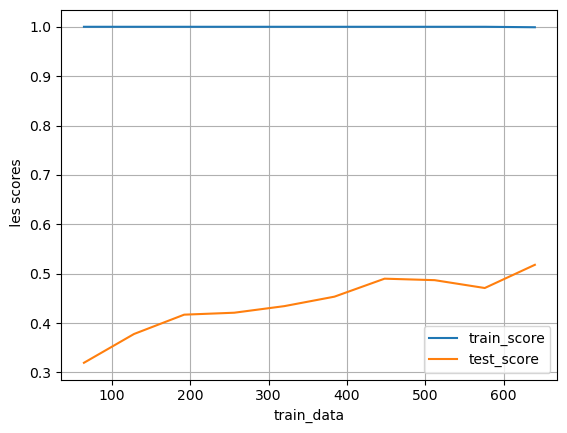

RandomForestClassifier ...


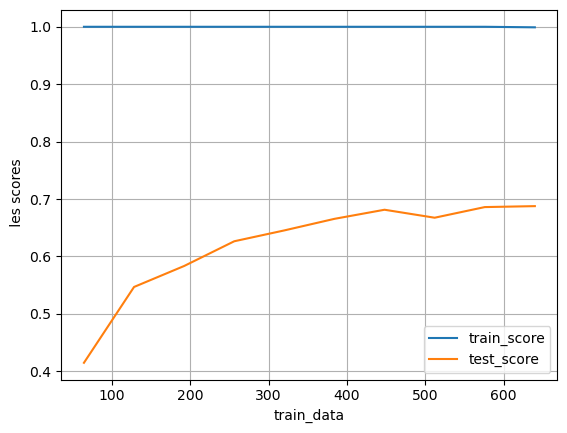

SVC ...


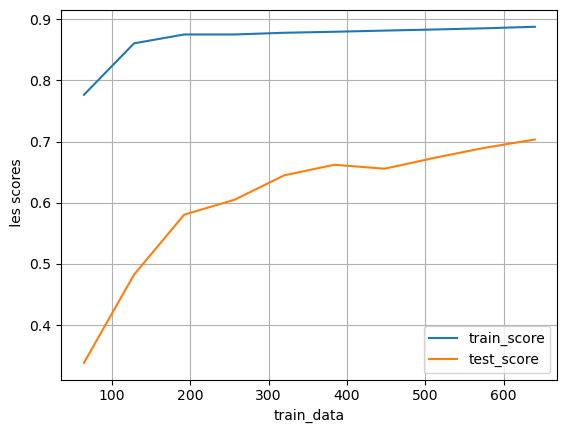

KNeighborsClassifier ...


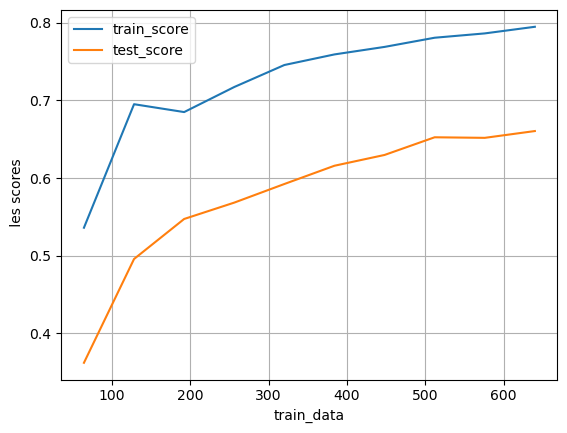

XGBClassifier ...


C:\Users\senaj\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
1 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\senaj\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\senaj\anaconda3\Lib\site-packages\xgboost\core.py", line 751, in inner_f
    return func(**kwargs)
  File "C:\Users\senaj\anaconda3\Lib\site-packages\xgboost\sklearn.py", line 1761, in fit
    raise ValueError(
    ...<2 lines>...
    )
ValueErr

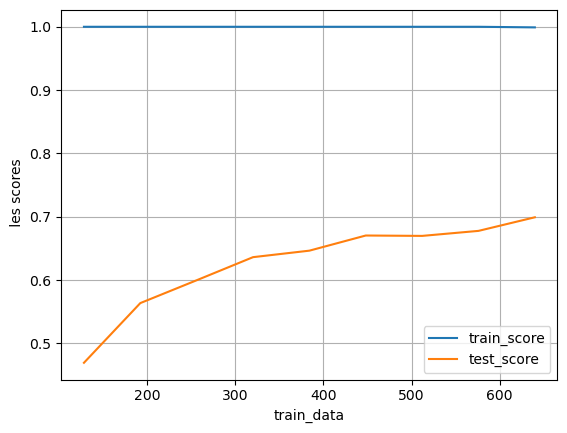

In [196]:
for name,model in modeles.items():
    print(name,"...")
    learningCurve(model,X_train_scaled,y_train_scaled)


A part le modèles de logisticRegression,
tous les autres sont en overfiting:
ils n'arrivent pas à généraliser.
Toutefois,le KNN s'améliore non seulement avec  le test_set ,
mais aussi sur le train_set.

# Recherche en grille

In [209]:

def recherche_grille(model, param, X_train, y_train, cv=5, scoring="f1_macro"):
    grid = GridSearchCV(estimator=model,param_grid=param,
    cv=cv,scoring=scoring,n_jobs=-1,verbose=0)
    grid.fit(X_train, y_train)
    print("Meilleur score :", grid.best_score_)
    print("Meilleurs paramètres :", grid.best_params_)
    return grid.best_estimator_

In [210]:
# je prends le regression logistic sur le test et les pairs correlées 
# je prends xgboost sur les tous sauf le pca
# je prends svc sur paires correlées et la sélection de variables
#je prends KNN sur la selection de variables 

In [211]:
logistic_reg_param = {"C":[0.001,0.01,0.1,1,10,100],"solver":["lbfgs","liblinear"],
                      "penalty":["l2"],"max_iter":[200,500,750,850,1000]}
svc_param = {"C":[0.1,1,5,10,20,50,100],"kernel":["rbf"],
    "gamma":[0.001,0.01,0.1,"scale","auto"]}

KNN_param = {"n_neighbors":[1,3,5,7,8,9,11,13,15],
    "weights":["uniform","distance"],"p":[1,2]}

xgboost_param = {"n_estimators":[100,200,300],"max_depth":[3,4,5,6],
    "learning_rate":[0.01,0.05,0.1],"subsample":[0.8,1],
    "colsample_bytree":[0.8,1],"min_child_weight":[1,3,5]}



In [212]:

modeles_liste = [logistic_reg_param,svc_param,KNN_param,xgboost_param]
models = modeles.copy()

In [213]:

del models['DecisionTreeClassifier']
del models['RandomForestClassifier']


Recherche en grille  sur données du test sans aucun feature engenering


In [214]:
from tqdm import  tqdm

In [215]:
# Evaluation sur données du test sans aucun feature engenering
for (name,model) , param in  tqdm(zip(models.items(),modeles_liste),desc="Optimisation des modèles", total=len(modeles)):
    print(name,"...")
    test_best_model =recherche_grille(model, param,
                                  X_train_scaled, y_train_scaled, cv=5, scoring="f1_macro")
    
    evaluation2(test_best_model,X_train_scaled,y_train_scaled,X_test_scaled,y_test_scaled)# retourne le f1-score et acc sur le testset
    

Optimisation des modèles:   0%|                                                                  | 0/6 [00:00<?, ?it/s]

LogisticRegression ...


Optimisation des modèles:  17%|█████████▋                                                | 1/6 [00:06<00:32,  6.46s/it]

Meilleur score : 0.7032222574651916
Meilleurs paramètres : {'C': 1, 'max_iter': 200, 'penalty': 'l2', 'solver': 'lbfgs'}
f1_score: 0.7107346142452526
accuracy_score: 0.71
SVC ...


Optimisation des modèles:  33%|███████████████████▎                                      | 2/6 [00:09<00:16,  4.17s/it]

Meilleur score : 0.7406719670233747
Meilleurs paramètres : {'C': 5, 'gamma': 'scale', 'kernel': 'rbf'}
f1_score: 0.765653528888147
accuracy_score: 0.765
KNeighborsClassifier ...


Optimisation des modèles:  50%|█████████████████████████████                             | 3/6 [00:09<00:08,  2.69s/it]

Meilleur score : 0.6997468680910364
Meilleurs paramètres : {'n_neighbors': 7, 'p': 1, 'weights': 'distance'}
f1_score: 0.7211061729987561
accuracy_score: 0.725
XGBClassifier ...
Meilleur score : 0.7281864826654437
Meilleurs paramètres : {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 0.8}


Optimisation des modèles:  67%|██████████████████████████████████████                   | 4/6 [57:03<28:31, 855.94s/it]

f1_score: 0.743728067540814
accuracy_score: 0.75


In [216]:
# Evaluation sur données du test avec les données du train 
# en prenant en compte la sélection de variables.
print("Pour la sélection de variables")
for (name,model) , param in  tqdm(zip(models.items(),modeles_liste),desc="Optimisation des modèles", total=len(modeles)):
    print(name,"...")
    test_best_model =recherche_grille(model, param,
                                      X_train_reduit, y_train_scaled, cv=5, scoring="f1_macro")
    evaluation2(test_best_model,X_train_reduit,y_train_scaled,X_test_reduit,y_test_scaled)# retourne le f1-score et acc sur le testset
        

Pour la sélection de variables


Optimisation des modèles:   0%|                                                                  | 0/6 [00:00<?, ?it/s]

LogisticRegression ...


Optimisation des modèles:  17%|█████████▋                                                | 1/6 [00:09<00:48,  9.78s/it]

Meilleur score : 0.6833239700370565
Meilleurs paramètres : {'C': 1, 'max_iter': 200, 'penalty': 'l2', 'solver': 'lbfgs'}
f1_score: 0.6838657396705619
accuracy_score: 0.685
SVC ...


Optimisation des modèles:  33%|███████████████████▎                                      | 2/6 [00:11<00:21,  5.28s/it]

Meilleur score : 0.7193129787384567
Meilleurs paramètres : {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
f1_score: 0.772176743388265
accuracy_score: 0.77
KNeighborsClassifier ...


Optimisation des modèles:  50%|█████████████████████████████                             | 3/6 [00:12<00:09,  3.26s/it]

Meilleur score : 0.6866082089871608
Meilleurs paramètres : {'n_neighbors': 8, 'p': 1, 'weights': 'distance'}
f1_score: 0.7237439292267792
accuracy_score: 0.725
XGBClassifier ...
Meilleur score : 0.705623795297175
Meilleurs paramètres : {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 0.8}


Optimisation des modèles:  67%|██████████████████████████████████████                   | 4/6 [45:31<22:45, 682.92s/it]

f1_score: 0.7354337269371689
accuracy_score: 0.74


In [219]:
# Evaluation sur données du test avec les données du train 
# débarrassées d'une des paires fortement correlées.
    
for (name,model) , param in  tqdm(zip(models.items(),modeles_liste),desc="Optimisation des modèles", total=len(modeles)):
    print(name,"...")
    test_best_model =recherche_grille(model, param,
                                      X_train_new, y_train_new, cv=5, scoring="f1_macro")
    evaluation2(test_best_model,X_train_new,y_train_new,X_test_new,y_test_new)# retourne le f1-score et acc sur le testset
        

Optimisation des modèles:   0%|                                                                  | 0/6 [00:00<?, ?it/s]

LogisticRegression ...


Optimisation des modèles:  17%|█████████▋                                                | 1/6 [00:10<00:52, 10.44s/it]

Meilleur score : 0.7053697889950762
Meilleurs paramètres : {'C': 1, 'max_iter': 200, 'penalty': 'l2', 'solver': 'lbfgs'}
f1_score: 0.7064557575273716
accuracy_score: 0.705
SVC ...


Optimisation des modèles:  33%|███████████████████▎                                      | 2/6 [00:12<00:22,  5.68s/it]

Meilleur score : 0.7468942627146451
Meilleurs paramètres : {'C': 5, 'gamma': 'scale', 'kernel': 'rbf'}
f1_score: 0.7594977608520612
accuracy_score: 0.76
KNeighborsClassifier ...


Optimisation des modèles:  50%|█████████████████████████████                             | 3/6 [00:13<00:10,  3.43s/it]

Meilleur score : 0.7046952155621018
Meilleurs paramètres : {'n_neighbors': 7, 'p': 1, 'weights': 'distance'}
f1_score: 0.7258646384245075
accuracy_score: 0.73
XGBClassifier ...
Meilleur score : 0.7380466625109425
Meilleurs paramètres : {'colsample_bytree': 1, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 3, 'n_estimators': 300, 'subsample': 0.8}


Optimisation des modèles:  67%|██████████████████████████████████████                   | 4/6 [55:31<27:45, 832.77s/it]

f1_score: 0.738738096664926
accuracy_score: 0.745


In [ ]:

svc_param = {"C":[0.1,1,5,10,20,50,100],"kernel":["rbf"],
    "gamma":[0.001,0.01,0.1,"scale","auto"]}

KNN_param = {"n_neighbors":[1,3,5,7,9,11,13,15],
    "weights":["uniform","distance"],"p":[1,2]}


In [ ]:
# je prends le regression logistic sur le test et les pairs correlées 
# je prends xgboost sur les tous sauf le pca
# je prends svc sur paires correlées et la sélection de variables
#je prends KNN sur la selection de variables 